## **Inflation pre-processing**

In [161]:
# Import of necessary packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as st
import json
import os

In [188]:
def params_to_json(prefix, mean, variance):
    """Adds descriptive statistics to json file"""
    json_path = "/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/relationships/statistics.json"
    params={}
    if os.path.exists(json_path):
        try:
            with open(json_path, "r") as f:
                params = json.load(f)
        except json.JSONDecodeError:
                pass
    params[f"{prefix}_mean"] = mean
    params[f"{prefix}_std"] = variance
    with open(json_path, "w") as f:
        json.dump(params, f)

In [163]:
# Import first part of inflation and rename, add columns
infl1 = pd.read_csv("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/inflation/INFL_95_17.csv")
infl1["Classification"] = "COICOP"
infl1.rename(columns={"Classification COICOP" : "Year"}, inplace=True)

In [164]:
# Import second part of inflation and rename, add columns
infl2 = pd.read_csv("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/inflation/INFL_18_24.csv")
infl2["Classification"] = "ECOICOP"
infl2.rename(columns={"Classification ECOICOP" : "Year"}, inplace=True)

In [165]:
# Union inflation data and reset index
infl = pd.concat([infl1, infl2]).reset_index()
infl.drop("index",axis=1, inplace=True)

In [166]:
# Transfer data such that Total for 1995 is 100
div = infl[infl['Year'] == 1995]['Total'][0]
infl["Total"] = np.round((infl["Total"] / div) * 100,1)

In [167]:
# Create year-to-year inflation in percentage 
infl["Inflation"] = np.nan
for i in range(1,len(infl)):
    infl.loc[i, "Inflation"] = np.round((infl.loc[i, "Total"] - infl.loc[i-1, "Total"]) / np.abs(infl.loc[i-1, "Total"]), 4)

In [168]:
# Check for Outliers
# Calculate mean, std
infl_std = np.std(infl["Inflation"])
infl_mean = np.mean(infl["Inflation"])

# Calculate Z-Score
infl["Z-Score"] = np.nan
for i in range(len(infl)):
    infl.loc[i, "Z-Score"] = ((infl.loc[i, "Inflation"] - infl_mean) / infl_std)

# Print out Outliers
infl[np.abs(infl["Z-Score"])>=3] # 2022

,Year,Total,Food and \nnon-alcoholic beverages,"Alcoholic beverages,\ntobacco",Clothing and footwear,"Housing, water, energy,\nfuel","Furnishings,\nhouseholds equipment\nand maintenance",Health,Transport,Post and telecommunication,Recreation and culture,Education,Restaurants and hotels,Miscellaneous goods and services,Classification,Inflation,Z-Score
27,2022,255.9,133.5,138.6,130.7,139.5,122.4,130.9,134.2,92.1,123.2,118.9,153.5,128.8,ECOICOP,0.1506,3.166046


### Check inflation for housing only

In [169]:
# Inflation of Housing only
house = pd.read_csv("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/inflation/Housing_inflation.csv")

In [170]:
# Transfer data such that Total for 1995 is 100
div_house = house[house['Year'] == 1996].iloc[0,1]
house["Total"] = np.round((house["Housing (2015=100)"] / div_house) * 100, 1)

In [171]:
# Change ordering such that it is the same as in infl
house = house.sort_values(by="Year").reset_index().drop("index", axis=1)

In [172]:
# Create year-to-year inflation in percentage 
house["Inflation"] = np.nan
for i in range(1,len(house)):
    house.loc[i, "Inflation"] = np.round((house.loc[i, "Total"] - house.loc[i-1, "Total"]) / np.abs(house.loc[i-1, "Total"]), 4)

### Combining

In [173]:
# Compare inflation of housing only and total inflation
np.mean(house[house["Year"]>1996]["Inflation"]), np.mean(infl[infl["Year"]>1996]["Inflation"])

(np.float64(0.04661071428571429), np.float64(0.03620357142857143))

In [174]:
# Contribution of inflation of housing to total inflation
house_weight = 0.103372152 # Number according to Consumer basket for CPI since January 2024 by Czech Statistical Office
whinfl24 = (house[house["Year"]==2024].iloc[0,3] * house_weight)
print(f"Inflation of housing contributes to total inflation by {round(whinfl24 * 100,4)}%")

Inflation of housing contributes to total inflation by 0.1158%


In [175]:
# Yearly inflation without housing
infl["Infl-Hous"] = infl["Inflation"] - whinfl24

In [196]:
# Check for Outliers
# Calculate mean, std
infl_std = np.std(infl["Inflation"])
infl_mean = np.mean(infl["Inflation"])

# Calculate Z-Score
infl["Z-Score"] = np.nan
for i in range(len(infl)):
    infl.loc[i, "Z-Score"] = ((infl.loc[i, "Inflation"] - infl_mean) / infl_std)

# Print out Outliers
infl[np.abs(infl["Z-Score"])>3] # 2022

,Year,Total,Food and \nnon-alcoholic beverages,"Alcoholic beverages,\ntobacco",Clothing and footwear,"Housing, water, energy,\nfuel","Furnishings,\nhouseholds equipment\nand maintenance",Health,Transport,Post and telecommunication,Recreation and culture,Education,Restaurants and hotels,Miscellaneous goods and services,Classification,Inflation,Z-Score,Infl-Hous,Log_inflation,Log_ih
27,2022,255.9,133.5,138.6,130.7,139.5,122.4,130.9,134.2,92.1,123.2,118.9,153.5,128.8,ECOICOP,0.1506,3.166046,0.149442,-1.893128,-1.900845


In [198]:
# Check for Outliers
# Calculate mean, std
infl_std = np.std(infl["Infl-Hous"])
infl_mean = np.mean(infl["Infl-Hous"])

# Calculate Z-Score
infl["Z-Score_house"] = np.nan
for i in range(len(infl)):
    infl.loc[i, "Z-Score_house"] = ((infl.loc[i, "Infl-Hous"] - infl_mean) / infl_std)

# Print out Outliers
infl[np.abs(infl["Z-Score_house"])>3] # 2022

,Year,Total,Food and \nnon-alcoholic beverages,"Alcoholic beverages,\ntobacco",Clothing and footwear,"Housing, water, energy,\nfuel","Furnishings,\nhouseholds equipment\nand maintenance",Health,Transport,Post and telecommunication,...,Education,Restaurants and hotels,Miscellaneous goods and services,Classification,Inflation,Z-Score,Infl-Hous,Log_inflation,Log_ih,Z-Score_house
27,2022,255.9,133.5,138.6,130.7,139.5,122.4,130.9,134.2,92.1,...,118.9,153.5,128.8,ECOICOP,0.1506,3.166046,0.149442,-1.893128,-1.900845,3.166046


In [193]:
# Display statistics
infl_mean = np.mean(infl["Inflation"])
infl_var = np.std(infl["Inflation"])
print(f"Inflation has mean {np.round(infl_mean, 4)} and variance {np.round(infl_var,4)}.")

Inflation has mean 0.038 and variance 0.0356.


In [195]:
# Display statistics
infl_mean_house = np.mean(infl["Infl-Hous"])
infl_var_house = np.std(infl["Infl-Hous"])
print(f"Inflation has mean {np.round(infl_mean_house, 4)} and variance {np.round(infl_var_house,4)}.")

Inflation has mean 0.0368 and variance 0.0356.


In [178]:
# Check for max and min infl
infl[infl["Inflation"] == np.max((infl["Inflation"]))], infl[infl["Inflation"] == np.min(infl["Inflation"])]

(    Year  Total  Food and \nnon-alcoholic beverages  \
 27  2022  255.9                               133.5   
 
     Alcoholic beverages,\ntobacco  Clothing and footwear  \
 27                          138.6                  130.7   
 
     Housing, water, energy,\nfuel  \
 27                          139.5   
 
     Furnishings,\nhouseholds equipment\nand maintenance  Health  Transport  \
 27                                              122.4     130.9      134.2   
 
     Post and telecommunication  Recreation and culture  Education  \
 27                        92.1                   123.2      118.9   
 
     Restaurants and hotels  Miscellaneous goods and services Classification  \
 27                   153.5                             128.8        ECOICOP   
 
     Inflation   Z-Score  Infl-Hous  
 27     0.1506  3.166046   0.149442  ,
    Year  Total  Food and \nnon-alcoholic beverages  \
 8  2003  148.1                                73.6   
 
    Alcoholic beverages,\ntobac

In [160]:
# Export Inflation to xlsx
infl.to_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/inflation/Inflation.xlsx")

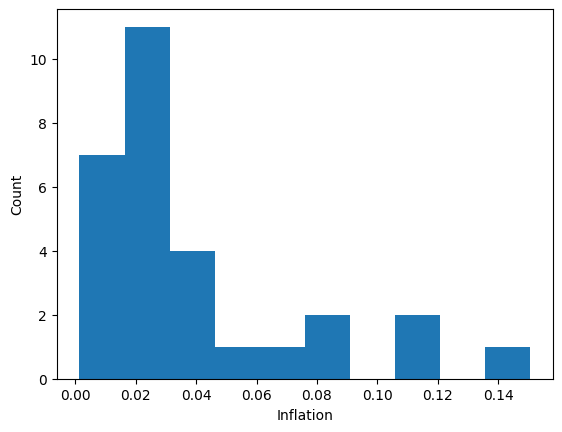

In [190]:
# Histogram of Inflation without Housing
plt.hist(infl["Inflation"])
plt.xlabel("Inflation")
plt.ylabel("Count")
plt.savefig("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/Visualizations/Inflation/Inflation_hist.pdf", format="pdf", bbox_inches="tight")
plt.show()

### **Log Normal Distribution**

In [203]:
# Log inflation with housing  
infl["Log_inflation"] = np.log(infl["Inflation"])

# Descriptive Statistics
sig2_log_infl = np.var(infl["Log_inflation"])
sigma_log_infl=np.std(infl["Log_inflation"], ddof=1)
mu_log_infl = np.mean(infl["Log_inflation"])
mu_log_infl, sigma_log_infl

(np.float64(-3.714200120417553), np.float64(1.0596641709618093))

In [189]:
params_to_json("Infl_log_total", np.round(mu_log_infl,4), np.round(sigma_log_infl,4))

In [207]:
# Log-transform the threshold
threshold_log = np.log(0.5)

# Prob that generated inflation is at least 0.5
z = (threshold_log - mu_log_infl) / sigma_log_infl
prob = 1 - st.norm.cdf(z)
prob

np.float64(0.002179419349745415)